# **LeNet-5로 MNIST분류하기**

LeNet-5는 1998년 얀 르쿤이 제안한 CNN초기 모델구조이다.
* 이후 컴퓨터 비전, 딥러닝 영역에서의 중요한 기초가 되었다.

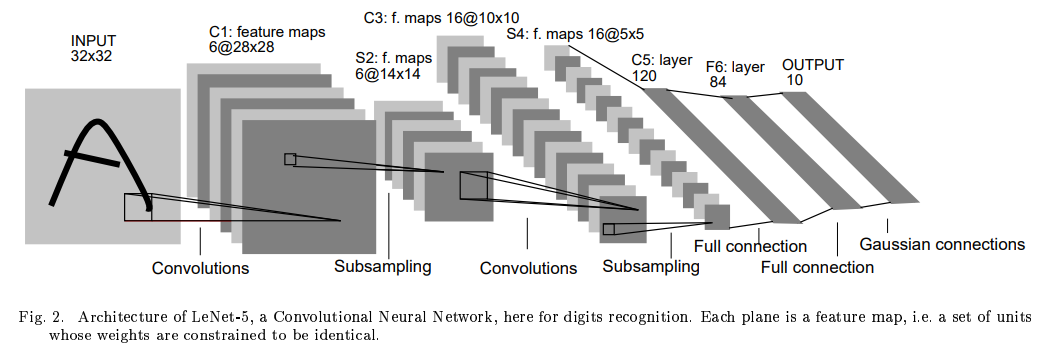

## **1998년 LeNet5 구조 설명**
- 출처 : wikipedia (https://en.wikipedia.org/wiki/LeNet#1998_LeNet)

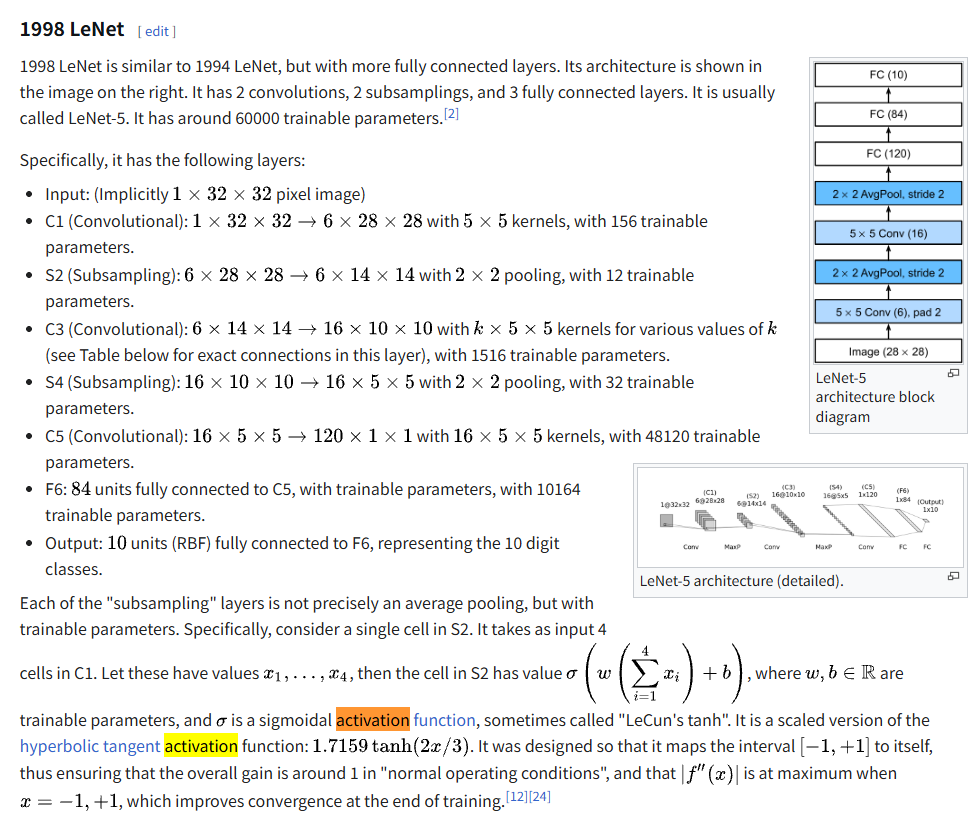

## **1. 환경세팅**

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms, datasets

# GPU 활용
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using PyTorch version:", torch.__version__,' Device:', DEVICE)

Using PyTorch version: 2.14.1+cu130  Device: cuda


## **2.데이터 준비하기**
* MNIST 데이터는 0~9까지의 손글씨로 이루어진 dataset이다.
 * 28x28 픽셀 사이즈로 되어있으며, 흑백이미지 이다.
* `torchvision` 라이브러리에서 가져올 수 있다.

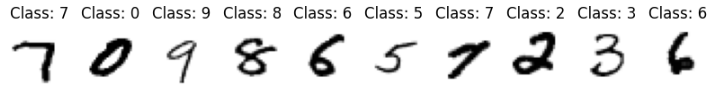

In [2]:
train_dataset = datasets.MNIST(root = "./MNIST",
                               train = True,
                               download = True,
                               transform = transforms.ToTensor())

test_dataset = datasets.MNIST(root = "./MNIST",
                              train = False,
                              download = True,
                              transform = transforms.ToTensor())

In [3]:
print(len(train_dataset.classes))
print(train_dataset.classes)

10
['0 - zero', '1 - one', '2 - two', '3 - three', '4 - four', '5 - five', '6 - six', '7 - seven', '8 - eight', '9 - nine']


각 파라미터는 아래의 의미를 가진다.
* `root`: 학습/테스트 데이터가 저장될 경로
* `train`: 학습용 데이터셋인지 테스트용 데이터셋인지 지정
* `download=True`: root에 데이터가 없으면 인터넷에서 다운로드
* `transform`과 `target_transform`: 특성(feature)과 레이블(label)에 적용할 변환을 지정


Dataset은 데이터셋의 특성(feature)과 레이블을 한 번에 한 샘플씩 가져온다.
하지만 모델을 학습시킬 땐 보통 다음이 필요하다.

* 샘플들을 "미니배치(minibatch)" 단위로 묶어서 전달하기
* 매 에폭마다 데이터를 다시 섞어서(reshuffle) 과적합(overfitting)을 줄이기

`DataLoader`는 이런 복잡한 부분들을 알아서 처리하고, 순회 가능한(iterable) 형태로 return 해준다.


In [4]:
train_loader = torch.utils.data.DataLoader(dataset = train_dataset,
                                           batch_size = 32,
                                           shuffle = True,
                                           pin_memory = (DEVICE.type == 'cuda'))

test_loader = torch.utils.data.DataLoader(dataset = test_dataset,
                                          batch_size = 32,
                                          shuffle = False,
                                          pin_memory = (DEVICE.type == 'cuda'))

**Q1. 한 batch(mini) 데이터의 shape를 확인하자.**
```
X_train, y_train = next(iter(train_loader))
```

그리고 tensor의 형태와 class의 개수를 확인하자.

In [5]:
# code here
X_train, y_train = next(iter(train_loader))
print(X_train.shape, y_train.shape)
print(len(train_loader))
print(len(test_loader))

torch.Size([32, 1, 28, 28]) torch.Size([32])
1875
313


**Q2. 현 batch의 10개의 데이터만 시각화해보자.**

```
plt.imshow()
```
- 흑백으로 그린다.

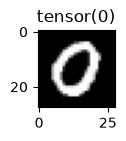

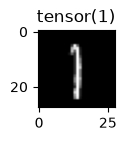

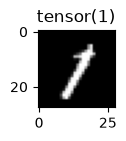

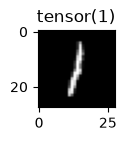

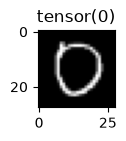

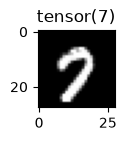

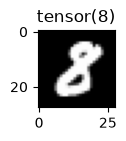

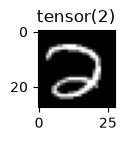

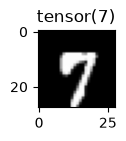

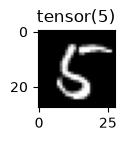

In [6]:
# code here

for i in range(10):
    plt.figure(figsize=(2,1))
    plt.imshow(X_train[i].flatten().reshape(28, 28), cmap = "gray")
    plt.title(y_train[i])
    plt.show()

## **3. 모델구조 구현하기**

* 논문에 기제된 모델구조 그대로 구현해보자.
- 각 학습 가능한 층 이후에는 ReLU 활성화 함수를 사용한다.

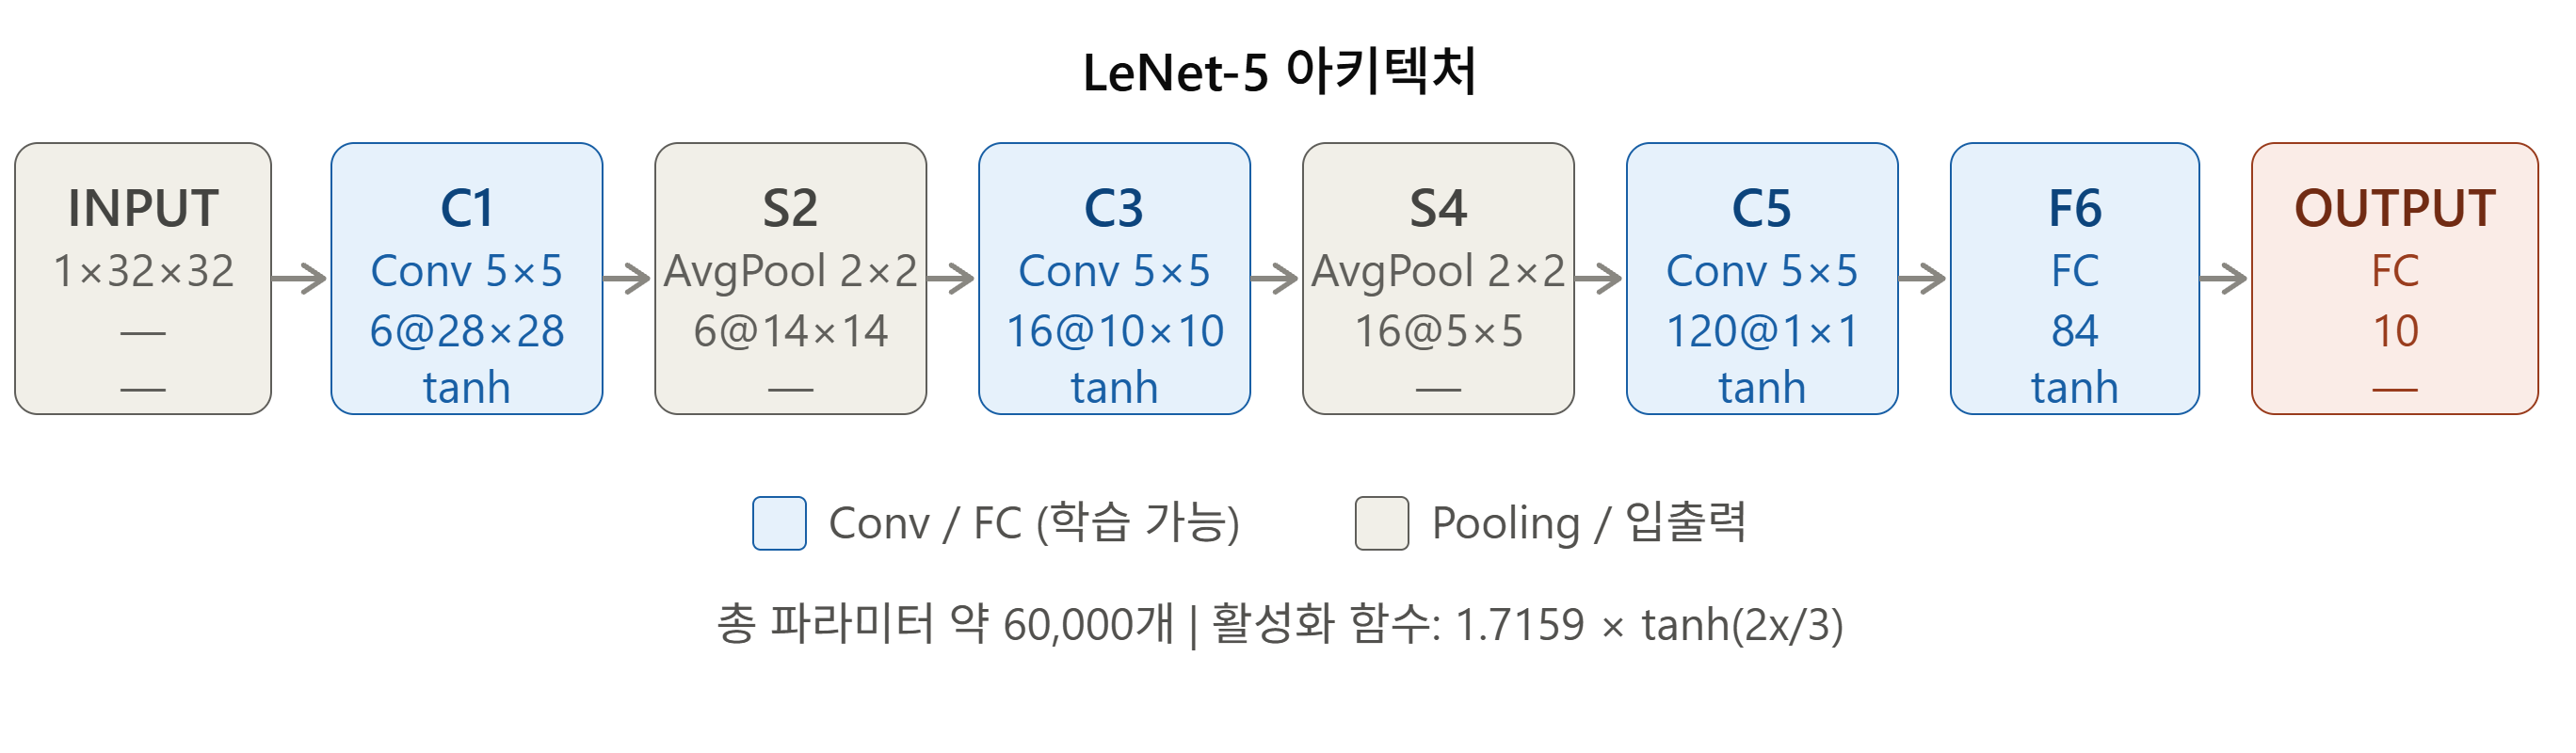

**Q1. 다음 질문에 대해 먼저 답하도록 한다.**

1. input -> conv1의 in_channels 값은?
2. input -> conv1의 out_channels 값은?
3. input -> conv1의 kernel 크기는?
4. input -> conv1의 padding 크기는?
5. input -> conv1의 stride 크기는?

모두 위 그래프에서 확인할 수 있다.
- 아래 코드창에 답을 기입하고 시작한다.

In [7]:
'''
1. input -> conv1의 in_channels 값은?   1
2. input -> conv1의 out_channels 값은?  6
3. input -> conv1의 kernel 크기는?      5
4. input -> conv1의 padding 크기는?     2
5. input -> conv1의 stride 크기는?      1
'''
print()

**Q2. LeNet5 CNN 모델을 구현한다.**
- 주의 : Linear layer로 넘어가기 전에는 반드시 flatten()을 해줘야 한다.

In [8]:
# code here
class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()
        self.convolution = nn.Sequential(
            # 1번 covolution
            nn.Conv2d(
                in_channels=1,
                out_channels=6,
                kernel_size=5,
                padding=2,
            ),
            nn.Tanh(),
            nn.AvgPool2d(
                kernel_size=2,
                stride = 2
            ),
            # 2번째 convolution layer
            nn.Conv2d(
                in_channels=6,
                out_channels=16,
                kernel_size=5,
            ),
            nn.Tanh(),
             nn.AvgPool2d(
                kernel_size=2,
                stride = 2
            ),
            nn.Conv2d(
                in_channels=16,
                out_channels=120,
                kernel_size=5,
            ),
            nn.Tanh()
        )

        # 신경망(분류부)를 만든다.
        self.network = nn.Sequential(
            # 일단 펴준다
            nn.Flatten(),
            #우리의 신경망에 들어가는 특징의 수는 120개
            nn.Linear(120, 84),
            nn.Tanh(),
            nn.Linear(84, 10)
        )

    def forward(self, X):
        z = self.convolution(X)
        a = self.network(z)
        return a

**Q3. 모델을 생성하고 layer의 정보를 출력해봅시다.**
- 모델을 GPU로 옮겨줍니다.

In [9]:
# code here
model = LeNet5()
print(model)

LeNet5(
  (convolution): Sequential(
    (0): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (1): Tanh()
    (2): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (3): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
    (4): Tanh()
    (5): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (6): Conv2d(16, 120, kernel_size=(5, 5), stride=(1, 1))
    (7): Tanh()
  )
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=120, out_features=84, bias=True)
    (2): Tanh()
    (3): Linear(in_features=84, out_features=10, bias=True)
  )
)


**Q4. X_train에서 첫 3개의 데이터만 model에 넣어보고, 출력되는 결과물의 shape를 출력해 봅시다.**

In [10]:
x = X_train[:3].to(DEVICE)


In [11]:
DEVICE

device(type='cuda')

In [12]:
model.to(DEVICE)

LeNet5(
  (convolution): Sequential(
    (0): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (1): Tanh()
    (2): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (3): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
    (4): Tanh()
    (5): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (6): Conv2d(16, 120, kernel_size=(5, 5), stride=(1, 1))
    (7): Tanh()
  )
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=120, out_features=84, bias=True)
    (2): Tanh()
    (3): Linear(in_features=84, out_features=10, bias=True)
  )
)

In [13]:
out = model(x)
print("입력 shape:", x.shape)
print("출력 shape:", out.shape)

입력 shape: torch.Size([3, 1, 28, 28])
출력 shape: torch.Size([3, 10])


In [14]:
x

tensor([[[[0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          ...,
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.]]],


        [[[0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          ...,
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.]]],


        [[[0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          ...,
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.]]]], device='cuda:0')


## **4.모델 학습**

* 모델학습시 주의할 점은 우리가 dataloader를 통해서 전체 데이터를 32개씩 미니배치로 나눠 두었다는 점이다.

* 즉, train_loader 전체를 둘러보면서, model에 학습을 시켜주어야한다.

* 이렇게 모든 데이터를 한번 다 둘러본것이 epoch 1회이다.

**Q1. 손실 함수는 CrossEntryopLoss()를 활용한다.**

In [15]:
model = LeNet5()
model.to(DEVICE)

LeNet5(
  (convolution): Sequential(
    (0): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (1): Tanh()
    (2): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (3): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
    (4): Tanh()
    (5): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (6): Conv2d(16, 120, kernel_size=(5, 5), stride=(1, 1))
    (7): Tanh()
  )
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=120, out_features=84, bias=True)
    (2): Tanh()
    (3): Linear(in_features=84, out_features=10, bias=True)
  )
)

In [16]:
# code here
criterion = nn.CrossEntropyLoss() # softmax + CE까지 같이 진행

**Q2. optimzer는 SGD를 활용한다.**
- learning rate : 0.01
- momentum : 0.9

In [17]:
# code here
optimizer = torch.optim.SGD(model.parameters(), lr = 0.01, momentum=0.9)

**Q3. 논문에서는 약 20 epoch 내외로 수렴했다고 했다.**

- epoch은 10번으로만 설정해보고, 학습을 진행해보자.
- 각 batch의 데이터는 학습 전, GPU로 옮겨줘야 한다.

In [18]:
# code here
epochs = 20
train_loss = []
test_loss = []

model.train()
for epoch in range(epochs):
    total_train_loss = 0
    total_test_loss = 0
    # 배치별 학습
    for xb, yb in train_loader:
        # 모델은 GPU로 가있음 -> 데이터도 GPU도 보내줘야 학습이 됨
        xb = xb.to(DEVICE)
        yb = yb.to(DEVICE)

        y_pred = model(xb)              # 순전파
        loss = criterion(y_pred, yb)    # softmax + loss
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # 지금 batch의 loss를 더해줌.
        total_train_loss += loss

    # batch별 test를 진행
    model.eval()
    for xb, yb in test_loader:
        xb = xb.to(DEVICE)
        yb = yb.to(DEVICE)

        with torch.no_grad():
            y_pred = model(xb)
            loss = criterion(y_pred, yb)
            total_test_loss += loss

    # 여기까지 오면 1번의 epoch이 끝남
    # train과 test loss쪽에 '평균'loss만 기록
    train_loss.append(total_train_loss / len(train_loader))
    test_loss.append(total_test_loss/ len(test_loader))

    print(f"epoch {epoch + 1} | train loss {train_loss[epoch]} | test loss {test_loss[epoch]}")

epoch 1 | train loss 0.32924583554267883 | test loss 0.09368261694908142
epoch 2 | train loss 0.0854170024394989 | test loss 0.062075067311525345
epoch 3 | train loss 0.05685392767190933 | test loss 0.050432927906513214
epoch 4 | train loss 0.044084034860134125 | test loss 0.049018505960702896
epoch 5 | train loss 0.03561927750706673 | test loss 0.040134817361831665
epoch 6 | train loss 0.02965667098760605 | test loss 0.038377147167921066
epoch 7 | train loss 0.024155734106898308 | test loss 0.04702942818403244
epoch 8 | train loss 0.02121024951338768 | test loss 0.036928460001945496
epoch 9 | train loss 0.017169004306197166 | test loss 0.037088315933942795
epoch 10 | train loss 0.01518324576318264 | test loss 0.03651612624526024
epoch 11 | train loss 0.012762387283146381 | test loss 0.035301338881254196
epoch 12 | train loss 0.010538104921579361 | test loss 0.04120917618274689
epoch 13 | train loss 0.009052453562617302 | test loss 0.03910116106271744
epoch 14 | train loss 0.0075545161

## **5.모델 평가**

**Q1. DataLoader에 들어있는 모든 테스트 데이터로 평가를 진행한다.**
- 평가 모드로 진입하고, test 데이터의 각 batch마다 GPU로 옮겨줘야 한다.
- 그리고 정확도를 구해준다.

In [19]:
# code here
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

## **6. 내가 그린 숫자**

**Q1. 그림판등을 통해 손으로 숫자 하나를 적고, 28 x 28 크기로 변환한다.**

- 그림판에서 ctrl + w 를 눌러 캔버스의 크기를 28 x 28로 맞춘다.
- bucket 툴로 배경을 검은색으로 칠한다.
- 흰색 브러시로 숫자를 그리고 현재 colab 파일에 해당 이미지를 업로드한다.
- 그리고는 아래 테스트 과정을 수행하여 결과를 확인한다.

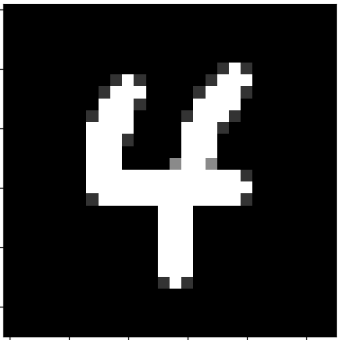

In [20]:
from PIL import Image
import torchvision.transforms as transforms

img = Image.open('2.png').convert('L')   # 흑백으로 변환

transform = transforms.Compose([
    transforms.Resize((28, 28)),          # 28×28로 resize
    transforms.ToTensor(),                # (H,W) → (1, H, W), 0~1 정규화
])

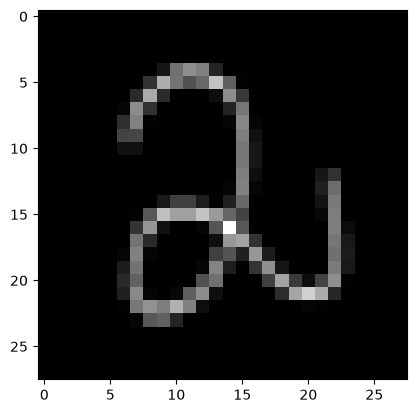

In [21]:
my_test = transform(img)
plt.imshow(my_test.flatten().reshape(28, 28), cmap='gray')
plt.show()

**Q1. 내 이미지의 크기를 (1, 1, 28, 28)로 변경하고, 모델에 넣어 예측 결과를 확인한다.**

In [26]:
my_test = my_test.reshape(1, 1, 28, 28)

In [29]:
#code here

model.eval()
with torch.no_grad():
    my_test = my_test.to(DEVICE)
    ans = model(my_test)
    print(ans)
    

tensor([[-8.7796,  4.6410,  9.2408,  3.2991, -6.3886,  4.3893, -0.0206, -3.6228,
          1.6700, -3.8546]], device='cuda:0')


In [27]:
my_test.shape

torch.Size([1, 1, 28, 28])

In [28]:
my_test.device

device(type='cpu')

In [30]:
train_dataset.classes[ans.argmax()]

'2 - two'